In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

PROJECT_DIR = Path.cwd().parent

DATA_PATH = (
    PROJECT_DIR
    / "data"mIn self-attention, Query and Key vectors are compared using dot products to calculate attention scores. The scores are then scaled and passed through softmax.
    / "raw"
    / "StudentPerformanceFactors.csv"
)

df = pd.read_csv(DATA_PATH)

In [2]:
import numpy as np

A = np.array([2,4,6])

B = np.array([3,5,7])

# Dot product
dot_product = np.dot(A, B)

# Euclidena distance
euclidean_distance = np.linalg.norm(A - B)

# Cosine similarity
cosine_similarity = (
    np.dot(A, B) /
    (np.linalg.norm(A) * np.linalg.norm(B))
)

print("Dot product:", dot_product)
print("Euclidean distance:", euclidean_distance)
print("Cosine similarity:", cosine_similarity)

Dot product: 68
Euclidean distance: 1.7320508075688772
Cosine similarity: 0.9974149030430577


In [4]:
df

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68


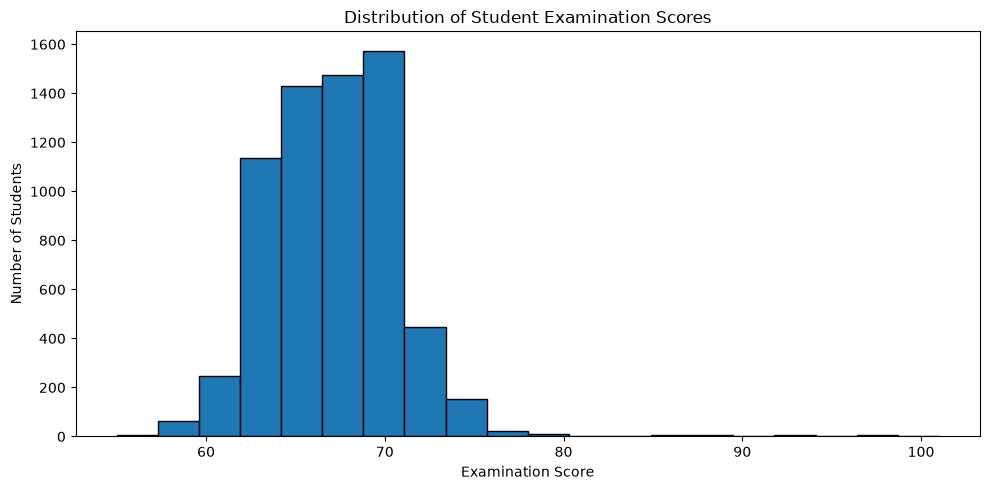

In [5]:
plt.figure(figsize=(10, 5))

plt.hist(
    df["Exam_Score"].dropna(),
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of Student Examination Scores")
plt.xlabel("Examination Score")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()

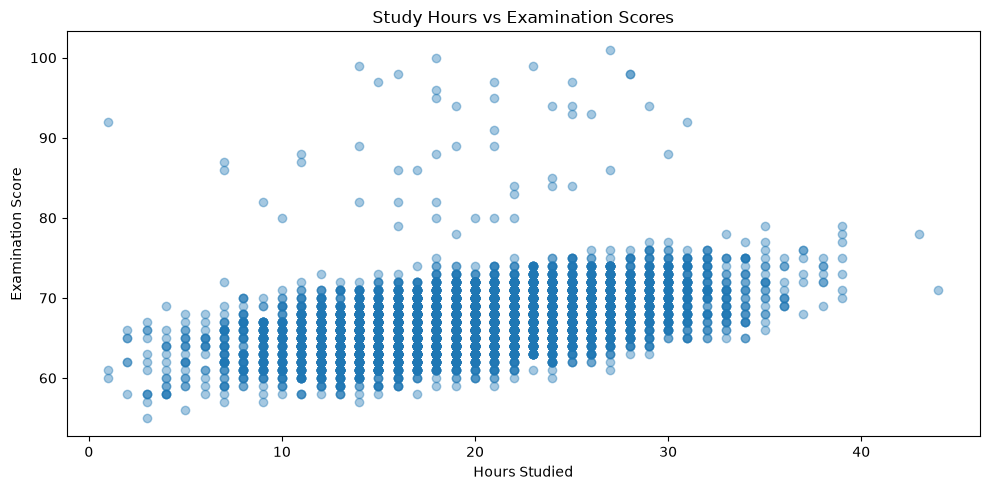

In [6]:
plt.figure(figsize=(10, 5))

plt.scatter(
    df["Hours_Studied"],
    df["Exam_Score"],
    alpha=0.4
)

plt.title("Study Hours vs Examination Scores")
plt.xlabel("Hours Studied")
plt.ylabel("Examination Score")

plt.tight_layout()
plt.show()

In [7]:
average_scores = (
    df.groupby("Motivation_Level")["Exam_Score"]
      .mean()
)

print(average_scores)

Motivation_Level
High      67.704321
Low       66.752194
Medium    67.330648
Name: Exam_Score, dtype: float64


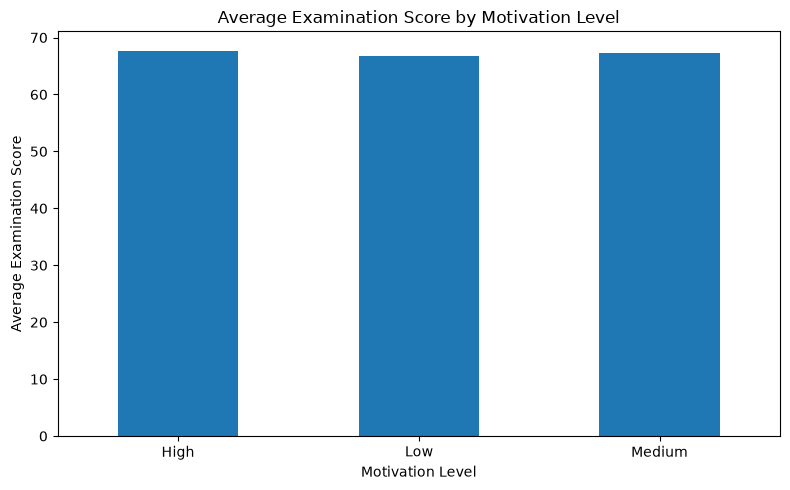

In [8]:
plt.figure(figsize=(8, 5))

average_scores.plot(kind="bar")

plt.title("Average Examination Score by Motivation Level")
plt.xlabel("Motivation Level")
plt.ylabel("Average Examination Score")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

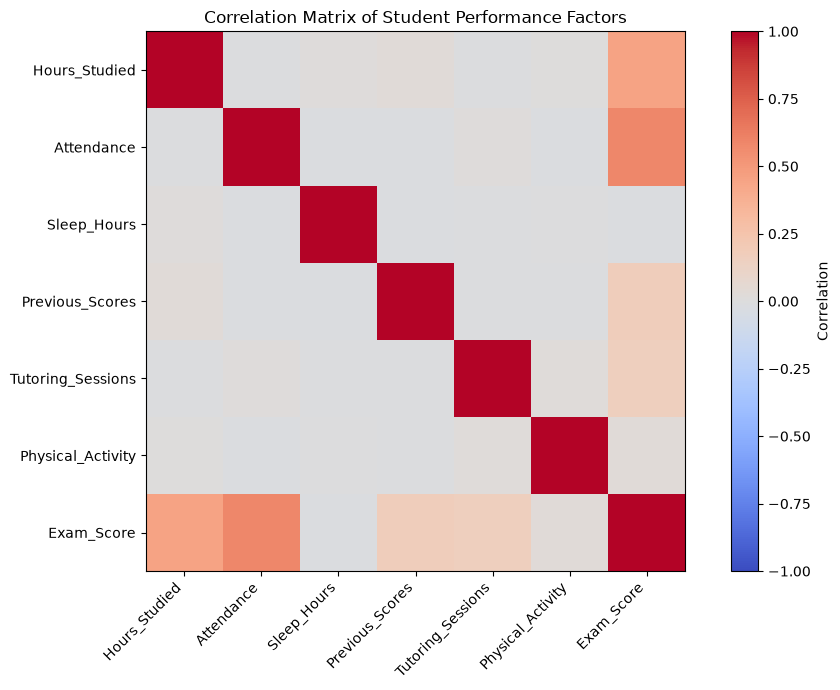

In [9]:
numeric_columns = [
    "Hours_Studied",
    "Attendance",
    "Sleep_Hours",
    "Previous_Scores",
    "Tutoring_Sessions",
    "Physical_Activity",
    "Exam_Score"
]

correlation_matrix = (
    df[numeric_columns].corr()
)

plt.figure(figsize=(10, 7))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(numeric_columns)),
    numeric_columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(numeric_columns)),
    numeric_columns
)

plt.title("Correlation Matrix of Student Performance Factors")
plt.tight_layout()
plt.show()